<a href="https://colab.research.google.com/github/Epot12/DLA_Lab3/blob/master/Lab3_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Working with Transformers in the HuggingFace Ecosystem

In this laboratory exercise we will learn how to work with the HuggingFace ecosystem to adapt models to new tasks. As you will see, much of what is required is *investigation* into the inner-workings of the HuggingFace abstractions. With a little work, a little trial-and-error, it is fairly easy to get a working adaptation pipeline up and running.

### Exercise 1: Sentiment Analysis (warm up)

In this first exercise we will start from a pre-trained BERT transformer and build up a model able to perform text sentiment analysis. Transformers are complex beasts, so we will build up our pipeline in several explorative and incremental steps.

#### Exercise 1.1: Dataset Splits and Pre-trained model
There are a many sentiment analysis datasets, but we will use one of the smallest ones available: the [Cornell Rotten Tomatoes movie review dataset](cornell-movie-review-data/rotten_tomatoes), which consists of 5,331 positive and 5,331 negative processed sentences from the Rotten Tomatoes movie reviews.

**Your first task**: Load the dataset and figure out what splits are available and how to get them. Spend some time exploring the dataset to see how it is organized. Note that we will be using the [HuggingFace Datasets](https://huggingface.co/docs/datasets/en/index) library for downloading, accessing, splitting, and batching data for training and evaluation.

NOTA: I commenti e le analisi relativi a questo notebook si trovano nel file Report_Lab3.pdf.

In [1]:
import torch
import wandb
import os
import numpy as np
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn import metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.svm import SVC
from datasets import load_dataset, get_dataset_split_names
from transformers import AutoTokenizer, AutoModel
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import TrainingArguments
from transformers import DataCollatorWithPadding
from transformers import Trainer
from peft import LoraConfig, get_peft_model
from peft import PromptTuningConfig

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
drive.mount('/content/drive')
drive_root="/content/drive/MyDrive/DLA_Lab3"
project_wandb = "DLA_Lab3"
wandb.login()

Using device: cuda
Mounted at /content/drive


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: emi_lore (emi_lore-university-of-florence) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [2]:
# Your code here.
ds_id = 'cornell-movie-review-data/rotten_tomatoes'
print(f"Split names del dataset: {get_dataset_split_names(ds_id)}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Split names del dataset: ['train', 'validation', 'test']


In [3]:
ds_train = load_dataset(ds_id, split='train')
ds_val = load_dataset(ds_id, split='validation')
ds_test = load_dataset(ds_id, split='test')


train.parquet:   0%|          | 0.00/699k [00:00<?, ?B/s]

validation.parquet:   0%|          | 0.00/90.0k [00:00<?, ?B/s]

test.parquet:   0%|          | 0.00/92.2k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

###Exploratory Data Analysis

In [ ]:
df_train = ds_train.to_pandas()

Nella cella seguente sono visualizzate le prime righe del dataset Rotten Tomatoes. Sono presenti sia il testo effettivo che le relative etichette (una per ogni recensione).

In [ ]:
print("Prime 5 righe del dataset:")
display(df_train.head())

Prime 5 righe del dataset:


,text,label
0,the rock is destined to be the 21st century's ...,1
1,"the gorgeously elaborate continuation of "" the...",1
2,effective but too-tepid biopic,1
3,if you sometimes like to go to the movies to h...,1
4,"emerges as something rare , an issue movie tha...",1


In [ ]:
print("\nEsempio casuale:")
sample = df_train.sample(1).iloc[0]
print(f"Testo: {sample['text']}")
print(f"Label: {sample['label']} (0=Negativo, 1=Positivo)")


Esempio casuale:
Testo: drowning's too good for this sucker .
Label: 0 (0=Negativo, 1=Positivo)


Nella cella superiore è stampato un sample del dataset con la relativa etichetta.

In [ ]:
class_counts = df_train['label'].value_counts()
print("\nDistribuzione delle classi:")
print(class_counts)


Distribuzione delle classi:
label
1    4265
0    4265
Name: count, dtype: int64


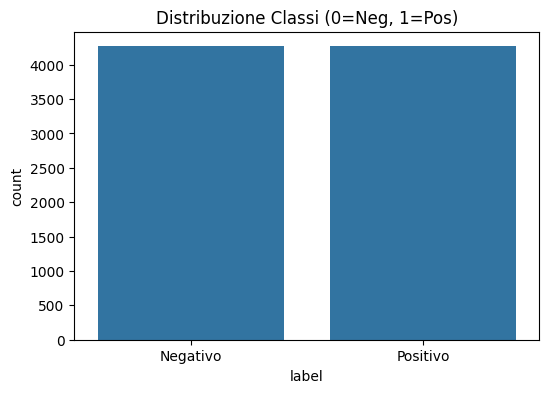

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df_train)
plt.title('Distribuzione Classi (0=Neg, 1=Pos)')
plt.xticks([0, 1], ['Negativo', 'Positivo'])
plt.savefig("distribuzione_classi_rotten_tomatoes.pdf", format="pdf", bbox_inches='tight')
plt.show()

In [ ]:
# Calcolo la lunghezza in parole (approssimazione dei token)
df_train['num_words'] = df_train['text'].apply(lambda x: len(x.split()))

In [ ]:
print("\nStatistiche sulla lunghezza delle frasi:")
print(df_train['num_words'].describe())


Statistiche sulla lunghezza delle frasi:
count    8530.000000
mean       20.992849
std         9.371094
min         1.000000
25%        14.000000
50%        20.000000
75%        27.000000
max        59.000000
Name: num_words, dtype: float64


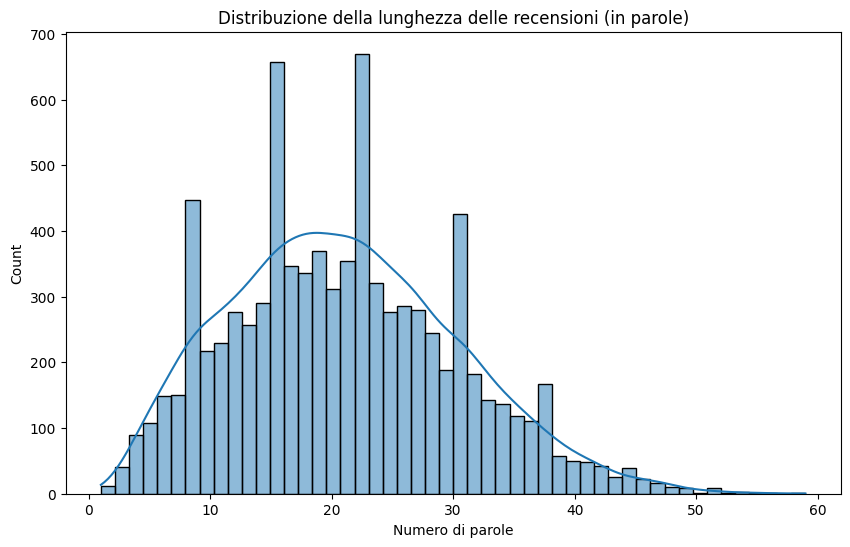

In [ ]:
# Istogramma della lunghezza
plt.figure(figsize=(10, 6))
sns.histplot(df_train['num_words'], bins=50, kde=True)
plt.title('Distribuzione della lunghezza delle recensioni (in parole)')
plt.xlabel('Numero di parole')
plt.savefig("lunghezza_recensioni_rotten_tomatoes.png", format="png", dpi=300, bbox_inches='tight')
plt.show()

#### Exercise 1.2: A Pre-trained BERT and Tokenizer

The model we will use is a *very* small BERT transformer called [Distilbert](https://huggingface.co/distilbert/distilbert-base-uncased) this model was trained (using self-supervised learning) on the same corpus as BERT but using the full BERT base model as a *teacher*.

**Your next task**: Load the Distilbert model and corresponding tokenizer. Use the tokenizer on a few samples from the dataset and pass the tokens through the model to see what outputs are provided. I suggest you use the [`AutoModel`](https://huggingface.co/transformers/v3.0.2/model_doc/auto.html) class (and the `from_pretrained()` method) to load the model and `AutoTokenizer` to load the tokenizer).

Nella cella seguente, carico il modello Distilbert.

In [4]:
# Your code here.
bert_id = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(bert_id)
distil_bert = AutoModel.from_pretrained(bert_id)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Nella cella seguente viene estratto un campione di frasi per osservare il dataset prima della tokenizzazione.

In [ ]:
samples = ds_train['text'][:2] #samples da passare nel modello
print(f"samples: {samples}")

samples: ['the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .', 'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .']


In [ ]:
inputs = tokenizer(samples, padding=True, truncation=True, return_tensors="pt")
print(f"inputs post tokenizer: {inputs}")

inputs post tokenizer: {'input_ids': tensor([[  101,  1996,  2600,  2003, 16036,  2000,  2022,  1996,  7398,  2301,
          1005,  1055,  2047,  1000, 16608,  1000,  1998,  2008,  2002,  1005,
          1055,  2183,  2000,  2191,  1037, 17624,  2130,  3618,  2084,  7779,
         29058,  8625, 13327,  1010,  3744,  1011, 18856, 19513,  3158,  5477,
          4168,  2030,  7112, 16562,  2140,  1012,   102,     0,     0,     0,
             0,     0],
        [  101,  1996,  9882,  2135,  9603, 13633,  1997,  1000,  1996,  2935,
          1997,  1996,  7635,  1000, 11544,  2003,  2061,  4121,  2008,  1037,
          5930,  1997,  2616,  3685, 23613,  6235,  2522,  1011,  3213,  1013,
          2472,  2848,  4027,  1005,  1055,  4423,  4432,  1997,  1046,  1012,
          1054,  1012,  1054,  1012, 23602,  1005,  1055,  2690,  1011,  3011,
          1012,   102]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 

Dall'output della cella sopra è possibile osservare come avviene il processo di tokenizzazione. Il tokenizer ha inserito i token speciali 101 e 102 per segnalare rispettivamente inizio e fine della frase (CLS e SEP) mentre, gli altri numeri, rappresentano i token del testo. Il tensore di 0 e 1 è una mappa che indica al modello quali numeri sono parole e quali padding.

In [ ]:
outputs = distil_bert(**inputs)

In [ ]:
print("\nTipo di output:", type(outputs))
print("Shape dell'ultimo stato nascosto:", outputs.last_hidden_state.shape)


Tipo di output: <class 'transformers.modeling_outputs.BaseModelOutput'>
Shape dell'ultimo stato nascosto: torch.Size([2, 52, 768])


In [ ]:
print(f"output del modello per il primo esempio: {outputs.last_hidden_state[0]}")

output del modello per il primo esempio: tensor([[-0.0332, -0.0168,  0.0194,  ...,  0.0476,  0.5834,  0.3036],
        [-0.0235, -0.0555, -0.3638,  ...,  0.1877,  0.5781, -0.1577],
        [-0.0516, -0.1014, -0.1511,  ...,  0.1503,  0.2649, -0.1575],
        ...,
        [ 0.3688, -0.1147,  0.8428,  ..., -0.0708, -0.0178, -0.2516],
        [ 0.0654, -0.0206,  0.1889,  ...,  0.1159,  0.2323, -0.2404],
        [ 0.0373, -0.0104,  0.1203,  ...,  0.1049,  0.2852, -0.3035]],
       grad_fn=<SelectBackward0>)


L'output del modello conferma che i dati sono stati processati correttamente attraverso i layer di Distilbert. Il tensore risultante ha dimensioni (Batch, Sequence, Features) pari a (2, 52, 768). Ciò significa che per ognuna delle 2 frasi, e per ognuno dei 52 token che le compongono, il modello ha prodotto un vettore denso di 768 caratteristiche (embeddings). Questi vettori rappresentano la comprensione semantica del testo da parte del modello e serviranno come input per il classificatore finale (la testa del modello).

#### Exercise 1.3: A Stable Baseline

In this exercise I want you to:
1. Use Distilbert as a *feature extractor* to extract representations of the text strings from the dataset splits;
2. Train a classifier (your choice, by an SVM from Scikit-learn is an easy choice).
3. Evaluate performance on the validation and test splits.

These results are our *stable baseline* -- the **starting** point on which we will (hopefully) improve in the next exercise.

**Hint**: There are a number of ways to implement the feature extractor, but probably the best is to use a [feature extraction `pipeline`](https://huggingface.co/tasks/feature-extraction). You will need to interpret the output of the pipeline and extract only the `[CLS]` token from the *last* transformer layer. *How can you figure out which output that is?*

In [5]:
# Your code here.
def tokenize(batch):
    return tokenizer(batch["text"], padding=True, truncation=True)

dataset = load_dataset(ds_id)

dataset_encoded = dataset.map(tokenize, batched=True, batch_size=None)

print("Colonne del dataset:", dataset_encoded.column_names)

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Colonne del dataset: {'train': ['text', 'label', 'input_ids', 'attention_mask'], 'validation': ['text', 'label', 'input_ids', 'attention_mask'], 'test': ['text', 'label', 'input_ids', 'attention_mask']}


In [6]:
dataset_encoded.set_format("torch", columns=["input_ids", "attention_mask", "label"])
model_d_bert = distil_bert.to(device)

La funzione presente nella cella seguente filtra le colonne del dataset e sposta i tensori sul device (GPU se presente). Oltre a ciò, viene disabilitato il calcolo dei gradienti, poiché Distilbert è usato solo come estrattore di features. Viene inoltre recuperato l'ultimo stato nascosto (last_hidden_state) e selezionato solo il vettore corrispondente al primo token (indice 0, ovvero il token CLS). Questo vettore funge da rappresentazione semantica condensata dell'intera frase.

In [7]:
def extract_hidden_states(batch):
    inputs = {k: v.to(device) for k, v in batch.items()
              if k in tokenizer.model_input_names}

    with torch.no_grad():
        last_hidden_state = model_d_bert(**inputs).last_hidden_state

    return {"hidden_state": last_hidden_state[:, 0].cpu().numpy()}

In [8]:
dataset_hidden = dataset_encoded.map(extract_hidden_states, batched=True)

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

In [ ]:
print("Nuove colonne:", dataset_hidden.column_names)

Nuove colonne: {'train': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'], 'validation': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'], 'test': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']}


Al dataset è stata aggiunta la colonna hidden_state.

In [ ]:
print(dataset_hidden)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'],
        num_rows: 1066
    })
})


In [ ]:
X_train = np.array(dataset_hidden["train"]["hidden_state"])
y_train = np.array(dataset_hidden["train"]["label"])

print(f"Dimensioni Features Train: {X_train.shape}")

Dimensioni Features Train: (8530, 768)


In [ ]:
X_val = np.array(dataset_hidden["validation"]["hidden_state"])
y_val = np.array(dataset_hidden["validation"]["label"])

print(f"Dimensioni Training: X={X_train.shape}, y={y_train.shape}")
print(f"Dimensioni Validation: X={X_val.shape}, y={y_val.shape}")

Dimensioni Training: X=(8530, 768), y=(8530,)
Dimensioni Validation: X=(1066, 768), y=(1066,)


In [ ]:
svm_clf = SVC(kernel='linear', C=1.0, random_state=42)
svm_clf.fit(X_train, y_train)
score = svm_clf.score(X_val, y_val)
print(f"\nAccuracy sul Validation Set: {score:.2%}")
y_preds = svm_clf.predict(X_val)


Accuracy sul Validation Set: 81.89%


In [ ]:
print(classification_report(y_val, y_preds, target_names=["Negativo", "Positivo"]))

              precision    recall  f1-score   support

    Negativo       0.80      0.85      0.82       533
    Positivo       0.84      0.79      0.81       533

    accuracy                           0.82      1066
   macro avg       0.82      0.82      0.82      1066
weighted avg       0.82      0.82      0.82      1066



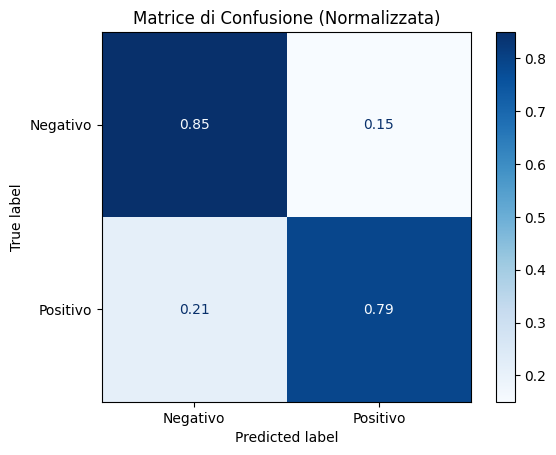

In [ ]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_preds,
    display_labels=["Negativo", "Positivo"],
    cmap=plt.cm.Blues,
    normalize='true' # Mostra le percentuali invece dei numeri assoluti
)
plt.title("Matrice di Confusione (Normalizzata)")
plt.savefig("confusion_matrix_svm.pdf", format="pdf", bbox_inches='tight')
plt.show()

In [ ]:
X_test = np.array(dataset_hidden["test"]["hidden_state"])
y_test = np.array(dataset_hidden["test"]["label"])
print(f"Dimensioni Test: X={X_test.shape}, y={y_test.shape}")

Dimensioni Test: X=(1066, 768), y=(1066,)


In [ ]:
test_score = svm_clf.score(X_test, y_test)
print(f"Accuracy sul Test Set (Baseline): {test_score:.2%}")

Accuracy sul Test Set (Baseline): 80.68%


In [ ]:
y_test_preds = svm_clf.predict(X_test)
print(classification_report(y_test, y_test_preds, target_names=["Negativo", "Positivo"]))

              precision    recall  f1-score   support

    Negativo       0.80      0.82      0.81       533
    Positivo       0.82      0.79      0.80       533

    accuracy                           0.81      1066
   macro avg       0.81      0.81      0.81      1066
weighted avg       0.81      0.81      0.81      1066



-----
### Exercise 2: Fine-tuning Distilbert

In this exercise we will fine-tune the Distilbert model to (hopefully) improve sentiment analysis performance.

#### Exercise 2.1: Token Preprocessing

The first thing we need to do is *tokenize* our dataset splits. Our current datasets return a dictionary with *strings*, but we want *input token ids* (i.e. the output of the tokenizer). This is easy enough to do my hand, but the HugginFace `Dataset` class provides convenient, efficient, and *lazy* methods. See the documentation for [`Dataset.map`](https://huggingface.co/docs/datasets/v3.5.0/en/package_reference/main_classes#datasets.Dataset.map).

**Tip**: Verify that your new datasets are returning for every element: `text`, `label`, `intput_ids`, and `attention_mask`.

In [9]:
# Your code here.
# Itera su tutte le chiavi disponibili (train, validation, test)
for split in dataset_hidden.keys():
    print(f"Colonne nello split '{split}': {dataset_hidden[split].column_names}")

Colonne nello split 'train': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']
Colonne nello split 'validation': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']
Colonne nello split 'test': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']


#### Exercise 2.2: Setting up the Model to be Fine-tuned

In this exercise we need to prepare the base Distilbert model for fine-tuning for a *sequence classification task*. This means, at the very least, appending a new, randomly-initialized classification head connected to the `[CLS]` token of the last transformer layer. Luckily, HuggingFace already provides an `AutoModel` for just this type of instantiation: [`AutoModelForSequenceClassification`](https://huggingface.co/transformers/v3.0.2/model_doc/auto.html#automodelforsequenceclassification). You will want you instantiate one of these for fine-tuning.

In [10]:
# Your code here.
model_d_bert_ft = AutoModelForSequenceClassification.from_pretrained(bert_id, num_labels=2)
model_d_bert_ft = model_d_bert_ft.to(device)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


#### Exercise 2.3: Fine-tuning Distilbert

Finally. In this exercise you should use a HuggingFace [`Trainer`](https://huggingface.co/docs/transformers/main/en/trainer) to fine-tune your model on the Rotten Tomatoes training split. Setting up the trainer will involve (at least):


1. Instantiating a [`DataCollatorWithPadding`](https://huggingface.co/docs/transformers/en/main_classes/data_collator) object which is what *actually* does your batch construction (by padding all sequences to the same length).
2. Writing an *evaluation function* that will measure the classification accuracy. This function takes a single argument which is a tuple containing `(logits, labels)` which you should use to compute classification accuracy (and maybe other metrics like F1 score, precision, recall) and return a `dict` with these metrics.  
3. Instantiating a [`TrainingArguments`](https://huggingface.co/docs/transformers/v4.51.1/en/main_classes/trainer#transformers.TrainingArguments) object using some reasonable defaults.
4. Instantiating a `Trainer` object using your train and validation splits, you data collator, and function to compute performance metrics.
5. Calling `trainer.train()`, waiting, waiting some more, and then calling `trainer.evaluate()` to see how it did.

**Tip**: When prototyping this laboratory I discovered the HuggingFace [Evaluate library](https://huggingface.co/docs/evaluate/en/index) which provides evaluation metrics. However I found it to have insufferable layers of abstraction and getting actual metrics computed. I suggest just using the Scikit-learn metrics...

In [11]:
# Your code here.
!pip install accelerate --upgrade

In [12]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def tokenize_basic(batch):
    return tokenizer(batch["text"], truncation=True)

dataset_basic = dataset.map(tokenize_basic, batched=True)

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

In [13]:
def evaluation(eval_pred):
    metrics = {}
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1) #scikit learn non accetta logits
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='binary' #in questo modo si controlla quanto il modello è bravo a trovare la classe positiva perché il Trainer vuole solo un valore ma noi abbiamo
        #due classi
    )
    acc = accuracy_score(labels, preds)
    metrics['accuracy'] = acc
    metrics['precision'] = precision
    metrics['recall'] = recall
    metrics['f1'] = f1
    return metrics


#### Full Fine Tuning standard di DistilBert

In [14]:
timestamp_d_bert_ft = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
run_name_d_bert_ft = f"distilbert-run-{timestamp_d_bert_ft}"

wandb.finish()

os.environ["WANDB_PROJECT"] = project_wandb
os.environ["WANDB_LOG_MODEL"] = "false"
os.environ["WANDB_WATCH"] = "all"

training_args_d_bert_ft = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/DLA_Lab3/{run_name_d_bert_ft}",          # Cartella dove salvare i checkpoint e il modello finale

    logging_strategy="steps", # Strategia di logging
    logging_steps=50,
    eval_strategy="steps",           # Valuta il modello sul validation set alla fine di ogni epoca
    eval_steps=100,
    save_strategy="steps",           # Salva un checkpoint del modello alla fine di ogni epoca. eval_strategy e save_strategy devono coincidere. è buona norma
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,     # Alla fine del training, ricarica il checkpoint con la loss migliore
    metric_for_best_model="eval_f1",
    greater_is_better=True,

    learning_rate=2e-5,              # La velocità di apprendimento (2e-5 è standard per BERT)
    per_device_train_batch_size=16,  # Quante frasi processare insieme
    per_device_eval_batch_size=16,   # Batch size per la validazione
    num_train_epochs=2,              # Quante volte rivedere tutto il dataset (2 o 3 dovrebbero bastare per il fine-tuning)
    weight_decay=0.01,               # Regolarizzazione per evitare l'overfitting

    fp16=True,                       # "Mixed Precision" (dovrebbe essere più veloce su GPU T4 di Colab)
    push_to_hub=False,               # per non caricare online su HuggingFace Hub (salvo solo in locale)
    report_to="wandb",                 # per loggare su weights and biases
    run_name=run_name_d_bert_ft         #nome di questo specifico esperimento (per wandb)
)

In [ ]:
model_d_bert_ft = AutoModelForSequenceClassification.from_pretrained(bert_id, num_labels=2)
model_d_bert_ft = model_d_bert_ft.to(device)

trainer_d_bert_ft = Trainer(
    model=model_d_bert_ft,          # il modello (AutoModelForSequenceClassification)
    args=training_args_d_bert_ft,             # configurazione per il training (inclusi wandb e output_dir)
    train_dataset=dataset_basic["train"],      # Dataset di training tokenizzato (senza padding statico)
    eval_dataset=dataset_basic["validation"],  # Dataset di validazione
    tokenizer=tokenizer,            # Il tokenizer (serve per salvare il vocab)
    data_collator=data_collator,    # Il collator che fa padding dinamico
    compute_metrics=evaluation
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-2817047748.py:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft = Trainer(


In [ ]:
trainer_d_bert_ft.train()

Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.493200,0.423656,0.814259,0.796460,0.844278,0.819672
200,0.388600,0.398321,0.823640,0.796902,0.868668,0.831239
300,0.408700,0.357612,0.839587,0.840226,0.838649,0.839437
400,0.398100,0.344268,0.859287,0.898129,0.810507,0.852071
500,0.355600,0.369379,0.840525,0.806071,0.896811,0.849023
600,0.242200,0.378166,0.850844,0.821306,0.896811,0.857399
700,0.235100,0.372748,0.856473,0.869650,0.838649,0.853868
800,0.236200,0.387248,0.860225,0.858209,0.863039,0.860617
900,0.267700,0.378448,0.851782,0.827225,0.889306,0.857143
1000,0.222000,0.362825,0.861163,0.876712,0.840525,0.858238


TrainOutput(global_step=1068, training_loss=0.32952277490708715, metrics={'train_runtime': 192.5225, 'train_samples_per_second': 88.613, 'train_steps_per_second': 5.547, 'total_flos': 215637261882480.0, 'train_loss': 0.32952277490708715, 'epoch': 2.0})

In [ ]:
trainer_d_bert_ft.evaluate()

{'eval_loss': 0.3872480094432831,
 'eval_accuracy': 0.8602251407129456,
 'eval_precision': 0.8582089552238806,
 'eval_recall': 0.8630393996247655,
 'eval_f1': 0.8606173994387278,
 'eval_runtime': 2.4319,
 'eval_samples_per_second': 438.333,
 'eval_steps_per_second': 27.55,
 'epoch': 2.0}

In [ ]:
wandb.finish()

eval/accuracy,▁▂▅█▅▆▇█▇██
eval/f1,▁▃▄▇▆▇▇█▇██
eval/loss,█▆▂▁▃▄▄▅▄▃▅
eval/precision,▁▁▄█▂▃▆▅▃▇▅
eval/recall,▄▆▃▁██▃▅▇▃▅
eval/runtime,▁▆▂▁▃▂▁▃█▁▂
eval/samples_per_second,▄▁▂█▂▂▅▂▁▄▂
eval/steps_per_second,▄▁▂█▂▂▅▂▁▄▂
train/epoch,▁▁▁▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇█████
train/global_step,▁▁▁▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇█████
+3,...


I risultati del fine tuning su Distil Bert sono buoni, però si osserva che, alla seconda epoca, inizia a manifestarsi un po' di overfitting, con la validation loss in aumento. Questo è abbastanza normale e, in ogni caso, il salvataggio automatico salva il miglior modello. Tale modello è sostanzialmente esente da overfitting. Le prestazioni di accuracy sono nel range dello stato dell'arte (82 - 85 %) per questo tipo di soluzioni. E' interessante notare come il modello baseline che sfrutta una SVM in output non fa molto peggio (81.89% sul validation set) e ha il pregio di richiedere un training molto più leggero.

-----
### Exercise 3: Choose at Least One


#### Exercise 3.1: Efficient Fine-tuning for Sentiment Analysis (easy)

In Exercise 2 we fine-tuned the *entire* Distilbert model on Rotten Tomatoes. This is expensive, even for a small model. Find an *efficient* way to fine-tune Distilbert on the Rotten Tomatoes dataset (or some other dataset).

**Hint**: You could check out the [HuggingFace PEFT library](https://huggingface.co/docs/peft/en/index) for some state-of-the-art approaches that should "just work". How else might you go about making fine-tuning more efficient without having to change your training pipeline from above?

In [15]:
# Funzione helper
def count_trainable_params(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parametri totali: {total_params}")
    print(f"Parametri addestrabili: {trainable_params}")
    print(f"Percentuale di parametri addestrabili: {100 * trainable_params / total_params:.4f}%")


#### LoRa

In [ ]:
# Your code here.

model_d_bert_ft2 = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
print(model_d_bert_ft2)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [ ]:
# configurazione LoRA
lora_config = LoraConfig(
    r=8,                 # rank della decomposizione
    lora_alpha=32,       # scaling factor
    target_modules=["q_lin", "v_lin"],  # quali matrici adattare
    lora_dropout=0.1,
    bias="none",
    task_type="SEQ_CLS" #sequence classification (sentiment analysis)
)

model_d_bert_ft2 = get_peft_model(model_d_bert_ft2, lora_config)


In [ ]:
timestamp_d_bert_ft2 = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
run_name_d_bert_ft2 = f"distilbert-ft2-run-{timestamp_d_bert_ft2}"


training_args_d_bert_ft2 = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/DLA_Lab3/{run_name_d_bert_ft2}",          # Cartella dove salvare i checkpoint e il modello finale

    logging_strategy="steps", # Strategia di logging
    logging_steps=50,
    eval_strategy="steps",           # Valuta il modello sul validation set alla fine di ogni epoca
    eval_steps=100,
    save_strategy="steps",           # Salva un checkpoint del modello alla fine di ogni epoca. eval_strategy e save_strategy devono coincidere. è buona norma
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,     # Alla fine del training, ricarica il checkpoint con la loss migliore
    metric_for_best_model="eval_f1",
    greater_is_better=True,

    learning_rate=2e-5,              # La velocità di apprendimento (2e-5 è standard per BERT)
    per_device_train_batch_size=16,  # Quante frasi processare insieme
    per_device_eval_batch_size=16,   # Batch size per la validazione
    num_train_epochs=2,              # Quante volte rivedere tutto il dataset (2 o 3 dovrebbero bastare per il fine-tuning)
    weight_decay=0.01,               # Regolarizzazione per evitare l'overfitting

    fp16=True,                       # "Mixed Precision" (dovrebbe essere più veloce su GPU T4 di Colab)
    push_to_hub=False,               # per non caricare online su HuggingFace Hub (salvo solo in locale)
    report_to="wandb",                 # per loggare su weights and biases
    run_name=run_name_d_bert_ft2         #nome di questo specifico esperimento (per wandb)
)

In [ ]:
trainer_d_bert_ft2 = Trainer(
    model=model_d_bert_ft2,              # modello LoRA
    args=training_args_d_bert_ft2,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)

/tmp/ipython-input-2113037987.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft2 = Trainer(


In [ ]:
print("=== Model FT2 (LoRA base) ===")
count_trainable_params(model_d_bert_ft2)

=== Model FT2 (LoRA base) ===
Parametri totali: 67694596
Parametri addestrabili: 739586
Percentuale di parametri addestrabili: 1.0925%


In [ ]:
wandb.finish()
trainer_d_bert_ft2.train()

Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.674100,0.658735,0.719512,0.854545,0.529081,0.653534
200,0.599300,0.553773,0.794559,0.798479,0.787992,0.793201
300,0.517800,0.458839,0.804878,0.852495,0.737336,0.790744
400,0.464100,0.436018,0.801126,0.822938,0.767355,0.794175
500,0.443100,0.428071,0.803940,0.810345,0.793621,0.801896
600,0.423700,0.423808,0.807692,0.824111,0.782364,0.802695
700,0.405000,0.422054,0.812383,0.836364,0.776735,0.805447
800,0.428400,0.419766,0.813321,0.815094,0.810507,0.812794
900,0.469400,0.417034,0.816135,0.825919,0.801126,0.813333
1000,0.426000,0.415554,0.812383,0.828402,0.787992,0.807692


TrainOutput(global_step=1068, training_loss=0.48361920194232955, metrics={'train_runtime': 98.2685, 'train_samples_per_second': 173.606, 'train_steps_per_second': 10.868, 'total_flos': 219335753967840.0, 'train_loss': 0.48361920194232955, 'epoch': 2.0})

In [ ]:
eval_results_d_bert_ft2 = trainer_d_bert_ft2.evaluate()
print("Risultati Validation LoRA:", eval_results_d_bert_ft2)
wandb.finish()

Risultati Validation LoRA: {'eval_loss': 0.41703397035598755, 'eval_accuracy': 0.8161350844277674, 'eval_precision': 0.8259187620889749, 'eval_recall': 0.801125703564728, 'eval_f1': 0.8133333333333334, 'eval_runtime': 2.3388, 'eval_samples_per_second': 455.789, 'eval_steps_per_second': 28.647, 'epoch': 2.0}


eval/accuracy,▁▆▇▇▇▇█████
eval/f1,▁▇▇▇▇██████
eval/loss,█▅▂▂▁▁▁▁▁▁▁
eval/precision,█▁█▄▂▄▆▃▄▅▄
eval/recall,▁▇▆▇█▇▇██▇█
eval/runtime,█▅▇▁▇▄▂▄▆▃▅
eval/samples_per_second,▁▂▁█▁▂▆▂▂▃▂
eval/steps_per_second,▁▂▁█▁▂▆▂▂▃▂
train/epoch,▁▁▁▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇█████
train/global_step,▁▁▁▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇█████
+3,...


In [ ]:
model_d_bert_ft3 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# Configurazione LoRA ottimizzata
lora_config2 = LoraConfig(
    r=16,                        # rank maggiore per avere maggiore capacità adattativa
    lora_alpha=32,                # scaling factor
    target_modules=["q_lin", "v_lin", "out_lin"],  # includo anche out_lin
    lora_dropout=0.15,            # dropout leggermente più alto
    bias="none",
    task_type="SEQ_CLS"
)

In [ ]:
# Applico LoRA al modello
model_d_bert_ft3 = get_peft_model(model_d_bert_ft3, lora_config2)

timestamp_d_bert_ft3 = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
run_name_d_bert_ft3 = f"distilbert-ft3-run-{timestamp_d_bert_ft3}"

training_args_d_bert_ft3 = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/DLA_Lab3/{run_name_d_bert_ft3}",
    logging_strategy="steps", # Strategia di logging
    logging_steps=50,
    eval_strategy="steps",           # Valuta il modello sul validation set alla fine di ogni epoca
    eval_steps=100,
    save_strategy="steps",           # Salva un checkpoint del modello alla fine di ogni epoca. eval_strategy e save_strategy devono coincidere. è buona norma
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,     # Alla fine del training, ricarica il checkpoint con la loss migliore
    metric_for_best_model="eval_f1",
    greater_is_better=True,

    learning_rate=3e-4,                  # learning rate leggermente più alto
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=4,                  # più epoche
    weight_decay=0.01,
    warmup_ratio=0.1,                    # warmup 10%
    lr_scheduler_type="cosine",          # scheduler coseno

    fp16=True,
    report_to="wandb",
    run_name=run_name_d_bert_ft3
)

In [ ]:
trainer_d_bert_ft3 = Trainer(
    model=model_d_bert_ft3,              # modello LoRA
    args=training_args_d_bert_ft3,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)

/tmp/ipython-input-4168323861.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft3 = Trainer(


In [ ]:
print("=== Model FT3 (LoRA ottimizzata) ===")
count_trainable_params(model_d_bert_ft3)


=== Model FT3 (LoRA ottimizzata) ===
Parametri totali: 67989508
Parametri addestrabili: 1034498
Percentuale di parametri addestrabili: 1.5216%


In [ ]:
wandb.finish()
trainer_d_bert_ft3.train()

Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.583400,0.455321,0.782364,0.823656,0.718574,0.767535
200,0.443300,0.393056,0.821764,0.817006,0.829268,0.823091
300,0.453200,0.381346,0.821764,0.849287,0.782364,0.814453
400,0.414700,0.356707,0.835835,0.849609,0.816135,0.832536
500,0.375900,0.371078,0.844278,0.837937,0.853659,0.845725
600,0.339300,0.376620,0.838649,0.804384,0.894934,0.847247
700,0.329700,0.392927,0.832083,0.865702,0.786116,0.823992
800,0.318000,0.393788,0.831144,0.816876,0.853659,0.834862
900,0.373600,0.339051,0.841463,0.856863,0.819887,0.837967
1000,0.331500,0.345615,0.837711,0.858566,0.808630,0.832850


TrainOutput(global_step=2136, training_loss=0.3190033859974436, metrics={'train_runtime': 285.3008, 'train_samples_per_second': 119.593, 'train_steps_per_second': 7.487, 'total_flos': 440982589175760.0, 'train_loss': 0.3190033859974436, 'epoch': 4.0})

In [ ]:
eval_results_ft3 = trainer_d_bert_ft3.evaluate()
print("Risultati Validation LoRA ft3:", eval_results_ft3)
wandb.finish()

Risultati Validation LoRA ft3: {'eval_loss': 0.3766203820705414, 'eval_accuracy': 0.8386491557223265, 'eval_precision': 0.8043844856661045, 'eval_recall': 0.8949343339587242, 'eval_f1': 0.8472468916518651, 'eval_runtime': 2.4003, 'eval_samples_per_second': 444.11, 'eval_steps_per_second': 27.913, 'epoch': 4.0}


eval/accuracy,▁▅▅▇█▇▇▇█▇▇████▇██▇▇▇▇
eval/f1,▁▆▅▇██▆▇▇▇▆██▇▇▇▇▇▇▇▇█
eval/loss,█▄▄▂▃▃▄▄▁▁▄▄▃▄▃▄▅▅▅▅▅▃
eval/precision,▃▂▆▆▄▁▇▂▆▇█▄▅▇▇▄▆▆▅▅▅▁
eval/recall,▁▅▄▅▆█▄▆▅▅▄▆▆▅▅▆▅▅▆▆▆█
eval/runtime,▁▄▃▁▃▇▁▄▃▁▇▆▃▅▆▃█▆▂▆█▃
eval/samples_per_second,█▂▃█▃▁▇▂▃▇▁▁▂▁▁▂▁▁▃▁▁▃
eval/steps_per_second,█▂▃█▃▁▇▂▃▇▁▁▂▁▁▂▁▁▃▁▁▃
train/epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████
train/global_step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇████
+3,...


Si osserva che usando LoRA con apposito fine tuning (ft3) si ottengono prestazioni sostanzialmente analoghe a quelle ottenute con il full fine tuning (ft). Questo è un ottimo risultato, in quanto con un metodo come LoRA, che addestra notevolmente meno parametri rispetto al full fine tuning, si ottengono prestazioni con esso comparabili e che sono prossime allo stato dell'arte. Il primo fine tuning con LoRA (ft2) ha dato prestazioni lievemente inferiori, probabilmente per il fatto che veniva aggiornato un numero troppo basso di parametri (solo q_lin e v_lin, quindi matrici di queries e values, trascurando out_lin proiezione di output dell'attenzione, addestrato invece in ft3).

In [15]:
sweep_config = {
    'method': 'random',  # random search rapido
    'metric': {'name': 'eval_f1', 'goal': 'maximize'},
    'parameters': {
        'learning_rate': {'min': 1e-5, 'max': 5e-4},
        'lora_r': {'values': [4, 8, 16]},
        'lora_alpha': {'values': [16, 32]},
        'lora_dropout': {'min': 0.05, 'max': 0.2},
        'num_train_epochs': {'values': [2, 3, 4]}
    }
}

sweep_id = wandb.sweep(sweep_config, project=project_wandb)


Create sweep with ID: lr1t6olv
Sweep URL: https://wandb.ai/emi_lore-university-of-florence/DLA_Lab3/sweeps/lr1t6olv


In [16]:
def train():
    run = wandb.init()
    config = wandb.config
    lr_str = f"{config.learning_rate:.0e}"
    timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    run_name = (
        f"lr-{lr_str}_"
        f"r-{config.lora_r}_"
        f"ep-{config.num_train_epochs}_"
        f"{timestamp}" # Mantengo l'ora per evitare sovrascritture se i parametri sono identici
    )

    wandb.run.name = run_name

    output_dir = f"/content/drive/MyDrive/DLA_Lab3/{run_name}"

    # Carico modello DistilBERT
    model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

    # Config LoRA con parametri dallo sweep
    lora_cfg = LoraConfig(
        r=config.lora_r,
        lora_alpha=config.lora_alpha,
        target_modules=["q_lin", "v_lin", "out_lin"],
        lora_dropout=config.lora_dropout,
        bias="none",
        task_type="SEQ_CLS"
    )

    model = get_peft_model(model, lora_cfg)

    # TrainingArguments
    training_args = TrainingArguments(
        output_dir=output_dir,
        logging_strategy="steps", # Strategia di logging
        logging_steps=50,
        eval_strategy="steps",           # Valuta il modello sul validation set alla fine di ogni epoca
        eval_steps=100,
        save_strategy="steps",           # Salva un checkpoint del modello alla fine di ogni epoca. eval_strategy e save_strategy devono coincidere. è buona norma
        save_steps=100,
        save_total_limit=2,
        load_best_model_at_end=True,     # Alla fine del training, ricarica il checkpoint con la loss migliore
        metric_for_best_model="eval_f1",
        greater_is_better=True,
        learning_rate=config.learning_rate,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=config.num_train_epochs,
        weight_decay=0.01,
        fp16=True,
        report_to="wandb",
        run_name=run_name
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=dataset_basic["train"],
        eval_dataset=dataset_basic["validation"],
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=evaluation
    )
    trainer.train()
    eval_results = trainer.evaluate()
    wandb.finish()



In [17]:
wandb.finish()
wandb.agent(sweep_id, function=train, count=20)  # count=20 esperimenti

wandb: Agent Starting Run: t4grlmjd with config:
wandb: 	learning_rate: 0.00015364163117786422
wandb: 	lora_alpha: 16
wandb: 	lora_dropout: 0.19041214693493763
wandb: 	lora_r: 16
wandb: 	num_train_epochs: 4
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-305139723.py:55: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.476800,0.427067,0.806754,0.810247,0.801126,0.805660
200,0.411400,0.394320,0.822702,0.833333,0.806754,0.819828
300,0.438400,0.374153,0.825516,0.840864,0.803002,0.821497
400,0.429400,0.379123,0.822702,0.889140,0.737336,0.806154
500,0.378900,0.398693,0.837711,0.801003,0.898687,0.847038
600,0.368200,0.366873,0.838649,0.810671,0.883677,0.845601
700,0.337100,0.362676,0.834897,0.878981,0.776735,0.824701
800,0.358600,0.367997,0.840525,0.835490,0.848030,0.841713
900,0.400400,0.343501,0.841463,0.843396,0.838649,0.841016
1000,0.341700,0.348484,0.838649,0.870637,0.795497,0.831373


eval/accuracy,▁▄▄▄▇▇▆▇▇▇██▇▇▇▇▇▇▇▇█▇
eval/f1,▁▃▄▁██▄▇▇▅▇▇▇▆▅▇▇▆▆▇▇█
eval/loss,█▅▄▄▆▃▃▃▁▂▁▂▁▂▁▁▂▂▁▁▁▆
eval/precision,▂▄▄█▁▂▇▄▄▇▇▅▄▆▆▄▄▅▄▄▄▁
eval/recall,▄▄▄▁█▇▃▆▅▄▄▅▆▄▄▆▅▄▅▆▆█
eval/runtime,█▇▇▅▄▂▅▁▅▂▁▄▅▆▃▆▇█▅▅▆▇
eval/samples_per_second,▁▂▂▄▅▆▃█▄▇█▅▄▃▆▃▂▁▄▄▃▁
eval/steps_per_second,▁▂▂▄▅▆▃█▄▇█▅▄▃▆▃▂▁▄▄▃▁
train/epoch,▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
train/global_step,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇████
+3,...


wandb: Agent Starting Run: 3ki9s0a7 with config:
wandb: 	learning_rate: 0.0003092106987334252
wandb: 	lora_alpha: 16
wandb: 	lora_dropout: 0.1553607846020283
wandb: 	lora_r: 8
wandb: 	num_train_epochs: 4
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-305139723.py:55: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


... (70 outputs left out)

wandb: Agent Starting Run: jgj3hxrd with config:
wandb: 	learning_rate: 0.00043546156049514086
wandb: 	lora_alpha: 16
wandb: 	lora_dropout: 0.08081719499341802
wandb: 	lora_r: 4
wandb: 	num_train_epochs: 3
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-305139723.py:55: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.455100,0.410333,0.812383,0.817143,0.804878,0.810964
200,0.395100,0.379392,0.827392,0.846918,0.799250,0.822394
300,0.433800,0.371955,0.820826,0.836614,0.797373,0.816523
400,0.410000,0.355697,0.834897,0.853465,0.808630,0.830443
500,0.375900,0.369195,0.846154,0.825397,0.878049,0.850909
600,0.333600,0.374560,0.837711,0.804054,0.893058,0.846222
700,0.323700,0.351919,0.834897,0.871102,0.786116,0.826430
800,0.325600,0.393128,0.841463,0.833333,0.853659,0.843373
900,0.359000,0.341143,0.840525,0.837989,0.844278,0.841121
1000,0.321900,0.350325,0.842402,0.870183,0.804878,0.836257


eval/accuracy,▁▄▃▆█▆▆▇▇▇▇█▇▇▇▇█
eval/f1,▁▃▂▄█▇▄▇▆▅▆▇▇▆▆▇█
eval/loss,█▅▄▂▄▄▂▆▁▂▂▄▄▄▂▃▄
eval/precision,▂▅▄▆▃▁█▄▄██▄▃▄▆▅▃
eval/recall,▂▂▂▂▇█▁▅▅▂▂▆▇▅▄▅▇
eval/runtime,▁▂▃▃▂▃▄█▅▂█▄▄▂▂▅▅
eval/samples_per_second,█▇▆▆▆▆▅▁▄▇▁▅▅▇▇▄▄
eval/steps_per_second,█▇▆▆▆▆▅▁▄▇▁▅▅▇▇▄▄
train/epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇█████
train/global_step,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
+3,...


In questa fase è stato utilizzato uno sweep con random search per esplorare lo spazio degli iperparametri di LoRA, in quanto efficace nell’individuare rapidamente regioni promettenti in spazi di ricerca eterogenei. I risultati mostrano una stabilità delle performance, con F1 compreso tra 0.82 e circa 0.85. Questo risultato è molto incoraggiante poiché, con solo l'1.5% dei parametri addestrati si ottengono prestazioni molto vicine al full fine tuning (ft) di DistilBERT.

Nelle celle seguenti è implementato uno sweep bayesiano sugli iperparametri di DistilBERT + LoRA per rifinire l'individuazione del miglior modello.

In [18]:
sweep_config2 = {
    "method": "bayes",
    "metric": {
        "name": "eval_f1",
        "goal": "maximize"
    },
    "parameters": {
        "learning_rate": {
            "min": 1e-4,
            "max": 4e-4
        },
        "lora_r": {
            "values": [4, 8]
        },
        "lora_alpha": {
            "value": 32
        },
        "lora_dropout": {
            "min": 0.08,
            "max": 0.16
        },
        "num_train_epochs": {
            "values": [3, 4]
        },
        "weight_decay": {
            "values": [0.0, 0.01]
        }
    }
}

sweep_id2 = wandb.sweep(
    sweep_config2,
    project=project_wandb
)

Create sweep with ID: m4s8ozbw
Sweep URL: https://wandb.ai/emi_lore-university-of-florence/DLA_Lab3/sweeps/m4s8ozbw


In [19]:
def train_bayes():
    run = wandb.init()
    config = wandb.config
    lr_str = f"{config.learning_rate:.0e}"
    timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    run_name = (
        f"sweep2-lr-{lr_str}_"
        f"r-{config.lora_r}_"
        f"ep-{config.num_train_epochs}_"
        f"{timestamp}" # Mantengo l'ora per evitare sovrascritture se i parametri sono identici
    )

    wandb.run.name = run_name

    output_dir = f"/content/drive/MyDrive/DLA_Lab3/{run_name}"

    model = AutoModelForSequenceClassification.from_pretrained(
        "distilbert-base-uncased",
        num_labels=2
    )

    lora_cfg = LoraConfig(
        r=config.lora_r,
        lora_alpha=config.lora_alpha,
        target_modules=["q_lin", "v_lin", "out_lin"],
        lora_dropout=config.lora_dropout,
        bias="none",
        task_type="SEQ_CLS"
    )

    model = get_peft_model(model, lora_cfg)

    training_args = TrainingArguments(
        output_dir=output_dir,
        logging_strategy="steps", # Strategia di logging
        logging_steps=50,
        eval_strategy="steps",           # Valuta il modello sul validation set alla fine di ogni epoca
        eval_steps=100,
        save_strategy="steps",           # Salva un checkpoint del modello alla fine di ogni epoca. eval_strategy e save_strategy devono coincidere. è buona norma
        save_steps=100,
        save_total_limit=2,
        load_best_model_at_end=True,     # Alla fine del training, ricarica il checkpoint con la loss migliore
        metric_for_best_model="eval_f1",
        greater_is_better=True,
        learning_rate=config.learning_rate,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=config.num_train_epochs,
        weight_decay=config.weight_decay,

        lr_scheduler_type="cosine",
        warmup_ratio=0.1,

        fp16=True,
        report_to="wandb",
        run_name=run_name
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=dataset_basic["train"],
        eval_dataset=dataset_basic["validation"],
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=evaluation
    )

    trainer.train()
    eval_results = trainer.evaluate()
    wandb.finish()


In [20]:
wandb.finish()
wandb.agent(
    sweep_id2,
    function=train_bayes,
    count=12
)

wandb: Agent Starting Run: z31gxl7j with config:
wandb: 	learning_rate: 0.00012080207064116548
wandb: 	lora_alpha: 32
wandb: 	lora_dropout: 0.08691840906536837
wandb: 	lora_r: 4
wandb: 	num_train_epochs: 3
wandb: 	weight_decay: 0.01
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-2139251370.py:59: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'weight_decay' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.650900,0.537068,0.775797,0.810127,0.720450,0.762661
200,0.431500,0.420994,0.814259,0.819048,0.806754,0.812854
300,0.442900,0.385753,0.825516,0.836893,0.808630,0.822519
400,0.425400,0.385569,0.819887,0.876380,0.744841,0.805274
500,0.376400,0.405060,0.833021,0.808696,0.872420,0.839350
600,0.356400,0.375261,0.835835,0.817376,0.864916,0.840474
700,0.340300,0.370358,0.838649,0.854617,0.816135,0.834933
800,0.351500,0.388617,0.839587,0.837687,0.842402,0.840037
900,0.387100,0.360534,0.834897,0.837429,0.831144,0.834275
1000,0.335300,0.366456,0.838649,0.861723,0.806754,0.833333


eval/accuracy,▁▅▆▆▇▇██▇█████▇▇█
eval/f1,▁▅▆▅██▇█▇▇▇███▇▇█
eval/loss,█▃▂▂▃▂▁▂▁▁▁▂▁▁▁▁▁
eval/precision,▁▂▄█▁▂▆▄▄▆▅▄▄▅▅▅▄
eval/recall,▁▅▅▂██▅▇▆▅▆▇▇▆▅▆▇
eval/runtime,▂▃▂▃▃▃▂▃▅▂▁█▂▄▃▃▁
eval/samples_per_second,▇▆▇▆▅▆▆▅▄▇█▁▆▅▆▆█
eval/steps_per_second,▇▆▇▆▅▆▆▅▄▇█▁▆▅▆▆█
train/epoch,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
train/global_step,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
+3,...


wandb: Agent Starting Run: wfyhlj70 with config:
wandb: 	learning_rate: 0.00028032020685835756
wandb: 	lora_alpha: 32
wandb: 	lora_dropout: 0.1237491366363749
wandb: 	lora_r: 4
wandb: 	num_train_epochs: 4
wandb: 	weight_decay: 0
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-2139251370.py:59: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'weight_decay' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


... (38 outputs left out)

wandb: Agent Starting Run: 12zwx6x7 with config:
wandb: 	learning_rate: 0.0003141222996449825
wandb: 	lora_alpha: 32
wandb: 	lora_dropout: 0.09524341727830624
wandb: 	lora_r: 4
wandb: 	num_train_epochs: 3
wandb: 	weight_decay: 0
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-2139251370.py:59: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'weight_decay' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.548800,0.438450,0.791745,0.828753,0.735460,0.779324
200,0.409000,0.410971,0.820826,0.796875,0.861163,0.827773
300,0.438000,0.386009,0.818949,0.818352,0.819887,0.819119
400,0.429600,0.367813,0.827392,0.870488,0.769231,0.816733
500,0.387200,0.366492,0.845216,0.830935,0.866792,0.848485
600,0.343100,0.378475,0.837711,0.808219,0.885553,0.845121
700,0.321400,0.360658,0.834897,0.875789,0.780488,0.825397
800,0.323900,0.375763,0.846154,0.841035,0.853659,0.847300
900,0.362600,0.341748,0.843340,0.854651,0.827392,0.840801
1000,0.322400,0.356449,0.844278,0.873727,0.804878,0.837891


eval/accuracy,▁▅▄▅▇▇▆█▇▇███████
eval/f1,▁▆▅▅█▇▅█▇▇▇███▇██
eval/loss,█▆▄▃▃▄▂▃▁▂▂▄▂▃▂▃▂
eval/precision,▄▁▃█▄▂█▅▆█▇▆▅▅▆▆▅
eval/recall,▁▇▅▃▇█▃▇▅▄▅▆▇▇▆▆▇
eval/runtime,▁█▅▃█▄▃▂▂▇▂▁▄▂▂▂▂
eval/samples_per_second,█▁▄▆▁▄▆▇▇▂▇█▄▇▇▇▇
eval/steps_per_second,█▁▄▆▁▄▆▇▇▂▇█▄▇▇▇▇
train/epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
train/global_step,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇█████
+3,...


Con lo sweep bayesiano si sono ottenute prestazioni di DistilBERT + LoRA molto vicine a quelle ottenute con il full fine tuning di DistilBERT.

#### Prompt tuning

In [16]:
model_d_bert_ft4 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

prompt_config = PromptTuningConfig(
    task_type="SEQ_CLS",          # sentiment analysis
    num_virtual_tokens=20,        # numero di soft prompt
    tokenizer_name_or_path="distilbert-base-uncased",
    num_layers=6,
    token_dim = 768,
    num_attention_heads=12
)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [17]:
model_d_bert_ft4.config


DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForMaskedLM"
  ],
  "attention_dropout": 0.1,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "hidden_dim": 3072,
  "initializer_range": 0.02,
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "transformers_version": "4.57.6",
  "vocab_size": 30522
}

In [18]:
model_d_bert_ft4 = get_peft_model(
    model_d_bert_ft4,
    prompt_config
)

In [19]:
model_d_bert_ft4.print_trainable_parameters()

trainable params: 607,490 || all params: 67,562,500 || trainable%: 0.8992


In [20]:
print("=== Model FT4 (prompt tuning) ===")
count_trainable_params(model_d_bert_ft4)

=== Model FT4 (prompt tuning) ===
Parametri totali: 67562500
Parametri addestrabili: 607490
Percentuale di parametri addestrabili: 0.8992%


In [21]:
timestamp_d_bert_ft4 = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
run_name_d_bert_ft4 = f"distilbert-run-ft4-{timestamp_d_bert_ft4}"

training_args_d_bert_ft4 = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/DLA_Lab3/{run_name_d_bert_ft4}",          # Cartella dove salvare i checkpoint e il modello finale

    logging_strategy="steps", # Strategia di logging
    logging_steps=50,
    eval_strategy="steps",           # Valuta il modello sul validation set alla fine di ogni epoca
    eval_steps=100,
    save_strategy="steps",           # Salva un checkpoint del modello alla fine di ogni epoca. eval_strategy e save_strategy devono coincidere. è buona norma
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,     # Alla fine del training, ricarica il checkpoint con la loss migliore
    metric_for_best_model="eval_f1",
    greater_is_better=True,

    learning_rate=2e-2,
    per_device_train_batch_size=16,  # Quante frasi processare insieme
    per_device_eval_batch_size=16,   # Batch size per la validazione
    num_train_epochs=6,
    weight_decay=0.01,               # Regolarizzazione per evitare l'overfitting

    fp16=True,                       # "Mixed Precision" (dovrebbe essere più veloce su GPU T4 di Colab)
    push_to_hub=False,               # per non caricare online su HuggingFace Hub (salvo solo in locale)
    report_to="wandb",                 # per loggare su weights and biases
    run_name=run_name_d_bert_ft4         #nome di questo specifico esperimento (per wandb)
)

In [22]:
trainer_d_bert_ft4 = Trainer(
    model=model_d_bert_ft4,
    args=training_args_d_bert_ft4,   # stessi args del ft
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)

/tmp/ipython-input-1134704705.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft4 = Trainer(


In [23]:
wandb.finish()
trainer_d_bert_ft4.train()


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.621900,0.483456,0.767355,0.858942,0.639775,0.733333
200,0.521200,0.473815,0.782364,0.739269,0.872420,0.800344
300,0.577300,0.434415,0.784240,0.883544,0.654784,0.752155
400,0.513800,0.425073,0.801126,0.824242,0.765478,0.793774
500,0.486300,0.432903,0.808630,0.828343,0.778612,0.802708
600,0.462600,0.470499,0.812383,0.803279,0.827392,0.815157
700,0.441800,0.411068,0.817073,0.847737,0.772983,0.808636
800,0.494000,0.426052,0.800188,0.888350,0.686679,0.774603
900,0.517800,0.400809,0.812383,0.819578,0.801126,0.810247
1000,0.433800,0.413115,0.812383,0.870824,0.733583,0.796334


TrainOutput(global_step=3204, training_loss=0.4607472302910689, metrics={'train_runtime': 368.0399, 'train_samples_per_second': 139.061, 'train_steps_per_second': 8.706, 'total_flos': 655330328790144.0, 'train_loss': 0.4607472302910689, 'epoch': 6.0})

In [24]:
eval_results_ft4 = trainer_d_bert_ft4.evaluate()
print("Risultati Validation Prompt Tuning:", eval_results_ft4)
path_final_ft4 = f"{training_args_d_bert_ft4.output_dir}/Best_Model_Final_ft4"
trainer_d_bert_ft4.save_model(path_final_ft4)
wandb.finish()

Risultati Validation Prompt Tuning: {'eval_loss': 0.39509648084640503, 'eval_accuracy': 0.8189493433395872, 'eval_precision': 0.8057553956834532, 'eval_recall': 0.8405253283302064, 'eval_f1': 0.82277318640955, 'eval_runtime': 2.2634, 'eval_samples_per_second': 470.981, 'eval_steps_per_second': 29.602, 'epoch': 6.0}


eval/accuracy,▁▃▃▅▆▆▇▅▆▆▄▆▆▇█▆▅▇█▆▇▇▇▆▇█▇██▇▇█▇
eval/f1,▁▆▂▆▆▇▇▄▇▆▃▅▅▇█▇▆██▇▇▇▇▇█▆▇▇▇▇▇▇█
eval/loss,▇▆▄▄▄▆▃▄▂▃▃▃█▂▂▃▃▂▂▂▂▂▂▂▂▁▁▁▂▁▁▁▂
eval/precision,▆▁▇▄▅▄▅▇▄▆▇▇█▅▅▅▅▄▅▅▆▅▅▄▄█▆▆▆▆▆▆▄
eval/recall,▁█▁▅▅▇▅▂▆▄▂▃▂▅▆▅▅▆▆▅▅▅▅▆▇▃▄▅▅▄▅▅▇
eval/runtime,▂▅▃▁▂▂▁▂▂▁▅▆▂▆▅▂▆▅▁▃▂▁▂▂▁█▄▁▃▃▁▃▂
eval/samples_per_second,▄▁▂█▃▃█▃▃▇▁▁▄▁▁▄▁▁▅▂▃█▃▃█▁▂▆▂▂▅▂▃
eval/steps_per_second,▄▁▂█▃▃█▃▃▇▁▁▄▁▁▄▁▁▅▂▃█▃▃█▁▂▆▂▂▅▂▃
train/epoch,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇█████
train/global_step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██████
+3,...


Dai risultati ottenuti si evince come il prompt tuning (ft5) dia prestazioni sensibilmente inferiori rispetto a LoRA o al full fine tuning. Questo risultato non è particolarmente inatteso, dal momento che il dataset in questione (Rotten Tomatoes) è piccolo e, soprattutto, il modello stesso (DistilBERT) è piccolo e quindi ha poca capacità latente frozen da sfruttare. Probabilmente aumentando il numero di token virtuali si potrebbe ottenere un avvicinamento delle prestazioni a quelle di LoRA ma questo non è conveniente, dal momento che LoRA si è già dimostrato la strada migliore e più vicina al full fine tuning (come prestazioni) tra i metodi testati.

#### Fine tuning con DistilBERT parzialmente congelato

Nel seguente esperimento viene effettuato un fine-tuning parziale di DistilBERT, in cui vengono congelati cinque dei sei layer transformer, mantenendo addestrabile l’ultimo layer insieme alla testa di classificazione. Gli embedding e il pre-classifier rimangono addestrabili.

In [25]:
model_d_bert_ft5 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=2
)

# Congelo tutti i layer del transformer
for layer in model_d_bert_ft5.distilbert.transformer.layer:
    for param in layer.parameters():
        param.requires_grad = False

# Sblocco solo l'ultimo layer del transformer
for param in model_d_bert_ft5.distilbert.transformer.layer[-1].parameters():
    param.requires_grad = True

#la testa di classificazione deve essere addestrabile
for param in model_d_bert_ft5.classifier.parameters():
    param.requires_grad = True

# Controllo parametri addestrabili
trainable_params_d_bert_ft5 = sum(p.numel() for p in model_d_bert_ft5.parameters() if p.requires_grad)
total_params_d_bert_ft5 = sum(p.numel() for p in model_d_bert_ft5.parameters())
print(f"Parametri addestrabili: {trainable_params_d_bert_ft5} ({100*trainable_params_d_bert_ft5/total_params_d_bert_ft5:.2f}%)")

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parametri addestrabili: 31515650 (47.07%)


In [26]:
timestamp_d_bert_ft5 = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
run_name_d_bert_ft5 = f"distilbert-run-ft5-{timestamp_d_bert_ft5}"

training_args_d_bert_ft5 = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/DLA_Lab3/{run_name_d_bert_ft5}",
    logging_strategy="steps",
    logging_steps=50,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True,

    learning_rate=1e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,

    fp16=True,
    push_to_hub=False,
    report_to="wandb",
    run_name=run_name_d_bert_ft5
)

In [27]:
trainer_d_bert_ft5 = Trainer(
    model=model_d_bert_ft5,
    args=training_args_d_bert_ft5,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)

/tmp/ipython-input-2803791447.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft5 = Trainer(


In [28]:
wandb.finish()
trainer_d_bert_ft5.train()

Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
100,0.449400,0.407723,0.808630,0.798548,0.825516,0.811808
200,0.382200,0.406935,0.821764,0.798261,0.861163,0.828520
300,0.430500,0.361740,0.836773,0.831793,0.844278,0.837989
400,0.413200,0.362768,0.837711,0.898230,0.761726,0.824365
500,0.364400,0.362846,0.838649,0.812825,0.879925,0.845045
600,0.245000,0.415009,0.838649,0.807496,0.889306,0.846429
700,0.226400,0.409598,0.843340,0.876543,0.799250,0.836114
800,0.203600,0.453378,0.851782,0.835420,0.876173,0.855311
900,0.263300,0.395849,0.844278,0.822496,0.878049,0.849365
1000,0.221100,0.393746,0.850844,0.868110,0.827392,0.847262


TrainOutput(global_step=1602, training_loss=0.26272085520174915, metrics={'train_runtime': 249.7119, 'train_samples_per_second': 102.478, 'train_steps_per_second': 6.415, 'total_flos': 323059008078528.0, 'train_loss': 0.26272085520174915, 'epoch': 3.0})

In [29]:
eval_results_d_bert_ft5 = trainer_d_bert_ft5.evaluate()
print("Risultati Validation Partial FT:", eval_results_d_bert_ft5)
path_final_ft5 = f"{training_args_d_bert_ft5.output_dir}/Best_Model_Final_ft5"
trainer_d_bert_ft5.save_model(path_final_ft5)
wandb.finish()

Risultati Validation Partial FT: {'eval_loss': 0.48819810152053833, 'eval_accuracy': 0.8564727954971857, 'eval_precision': 0.8584905660377359, 'eval_recall': 0.8536585365853658, 'eval_f1': 0.8560677328316086, 'eval_runtime': 5.0114, 'eval_samples_per_second': 212.714, 'eval_steps_per_second': 13.369, 'epoch': 3.0}


eval/accuracy,▁▃▅▅▅▅▆▇▆▇█▇█▇▇▇█
eval/f1,▁▄▅▃▆▆▅█▇▇█▇█▇▇▇█
eval/loss,▃▃▁▁▁▃▃▅▂▂▄█▆█▇▇▆
eval/precision,▁▁▃█▂▂▆▄▃▆▆▅▅▅▅▅▅
eval/recall,▄▆▆▁▇█▃▇▇▅▆▅▆▆▆▆▆
eval/runtime,▁▃▃▁▃▃▂▄▆▁▃▃▃▆█▂▅
eval/samples_per_second,▇▃▃█▂▂▄▂▁▆▃▂▂▁▁▅▁
eval/steps_per_second,▇▃▃█▂▂▄▂▁▆▃▂▂▁▁▅▁
train/epoch,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
train/global_step,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
+3,...


Di seguito il codice per addestrare solo la testa di classificazione di DistilBERT mantenendo tutto il resto congelato.

In [ ]:
model_d_bert_ft6 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=2
)

# Congelo tutti i layer del transformer
for param in model_d_bert_ft6.distilbert.parameters():
    param.requires_grad = False

# Rendo addestrabile solo la testa di classificazione
for param in model_d_bert_ft6.classifier.parameters():
    param.requires_grad = True

# Controllo parametri addestrabili
trainable_params_d_bert_ft6 = sum(p.numel() for p in model_d_bert_ft6.parameters() if p.requires_grad)
total_params_d_bert_ft6 = sum(p.numel() for p in model_d_bert_ft6.parameters())
print(f"Parametri addestrabili: {trainable_params_d_bert_ft6} ({100*trainable_params_d_bert_ft6/total_params_d_bert_ft6:.2f}%)")


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parametri addestrabili: 592130 (0.88%)


In [ ]:
timestamp_d_bert_ft6 = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
run_name_d_bert_ft6 = f"distilbert-run-ft6-{timestamp_d_bert_ft6}"

training_args_d_bert_ft6 = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/DLA_Lab3/{run_name_d_bert_ft6}",

    logging_strategy="steps",
    logging_steps=50,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True,

    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,

    fp16=True,
    push_to_hub=False,
    report_to="wandb",
    run_name=run_name_d_bert_ft6
)

In [ ]:
trainer_d_bert_ft6 = Trainer(
    model=model_d_bert_ft6,
    args=training_args_d_bert_ft6,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)



/tmp/ipython-input-3906102976.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft7 = Trainer(


In [ ]:
wandb.finish()
trainer_d_bert_ft6.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.650900,0.597218,0.743902,0.724913,0.786116,0.754275
2,0.591700,0.567938,0.762664,0.768199,0.752345,0.760190


TrainOutput(global_step=1068, training_loss=0.6194792472467887, metrics={'train_runtime': 21.7777, 'train_samples_per_second': 783.369, 'train_steps_per_second': 49.041, 'total_flos': 215637261882480.0, 'train_loss': 0.6194792472467887, 'epoch': 2.0})

In [ ]:
eval_results_d_bert_ft6 = trainer_d_bert_ft6.evaluate()
print("Risultati Validation Partial FT:", eval_results_d_bert_ft6)
path_final_ft6 = f"{training_args_d_bert_ft6.output_dir}/Best_Model_Final_ft6"
trainer_d_bert_ft5.save_model(path_final_ft5)


Risultati Validation Partial FT: {'eval_loss': 0.5679382085800171, 'eval_accuracy': 0.7626641651031895, 'eval_precision': 0.7681992337164751, 'eval_recall': 0.7523452157598499, 'eval_f1': 0.7601895734597156, 'eval_runtime': 0.6787, 'eval_samples_per_second': 1570.692, 'eval_steps_per_second': 98.721, 'epoch': 2.0}


Il seguente codice implementa un fine tuning parziale di DistilBERT, congelando embeddings e la maggior parte dei layer transformer. Vengono mantenuti addestrabili esclusivamente l’ultimo layer transformer, il pre-classifier e la testa di classificazione.

In [ ]:
from transformers import AutoModelForSequenceClassification

model_d_bert_ft8 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=2
)

# Congela TUTTO DistilBERT (embeddings + transformer)
for param in model_d_bert_ft8.distilbert.parameters():
    param.requires_grad = False

# Sblocca SOLO l’ultimo transformer layer
for param in model_d_bert_ft8.distilbert.transformer.layer[-1].parameters():
    param.requires_grad = True

# Sblocca testa di classificazione
for param in model_d_bert_ft8.pre_classifier.parameters():
    param.requires_grad = True

for param in model_d_bert_ft8.classifier.parameters():
    param.requires_grad = True

# Controllo
trainable_d_bert_ft8 = sum(p.numel() for p in model_d_bert_ft8.parameters() if p.requires_grad)
total_d_bert_ft8 = sum(p.numel() for p in model_d_bert_ft8.parameters())
print(f"Trainable: {trainable_d_bert_ft8} ({100*trainable_d_bert_ft8/total_d_bert_ft8:.2f}%)")


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable: 7680002 (11.47%)


In [ ]:
from transformers import Trainer

model_d_bert_ft8 = model_d_bert_ft8.to(device)

trainer_d_bert_ft8 = Trainer(
    model=model_d_bert_ft8,
    args=training_args_d_bert_ft,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)

/tmp/ipython-input-2182629699.py:5: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft8 = Trainer(


In [ ]:
trainer_d_bert_ft8.train()


wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'weight_decay' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.485200,0.377417,0.832083,0.852590,0.803002,0.827053
2,0.398900,0.372628,0.831144,0.859470,0.791745,0.824219


TrainOutput(global_step=1068, training_loss=0.43931064712867307, metrics={'train_runtime': 81.9347, 'train_samples_per_second': 208.215, 'train_steps_per_second': 13.035, 'total_flos': 215637261882480.0, 'train_loss': 0.43931064712867307, 'epoch': 2.0})

In [ ]:
eval_results_ft8 = trainer_d_bert_ft8.evaluate()
print("Risultati Validation FT8:", eval_results_ft8)

Risultati Validation FT8: {'eval_loss': 0.3774173855781555, 'eval_accuracy': 0.8320825515947468, 'eval_precision': 0.852589641434263, 'eval_recall': 0.8030018761726079, 'eval_f1': 0.8270531400966183, 'eval_runtime': 0.6741, 'eval_samples_per_second': 1581.322, 'eval_steps_per_second': 99.389, 'epoch': 2.0}


In questo ultimo caso le prestazioni sono molto buone e vicine a quelle di DistilBERT + LoRA e di DistilBERT full fine tuned. Si tratta comunqunque di prestazioni ottenute con un modello che ha l'11% dei parametri addestrabili, mentre LoRA ha solo l'1,5% dei parametri addestrabili.

#### BERT base e LoRA

In [ ]:
model_bert_ft = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)
print(model_bert_ft)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

In [ ]:
# Numero totale di parametri
total_params = sum(p.numel() for p in model_bert_ft.parameters())

# Numero di parametri addestrabili
trainable_params = sum(p.numel() for p in model_bert_ft.parameters() if p.requires_grad)

print(f"Parametri totali: {total_params}")
print(f"Parametri addestrabili: {trainable_params}")
print(f"Percentuale di parametri addestrabili: {100 * trainable_params / total_params:.2f}%")


Parametri totali: 109483778
Parametri addestrabili: 109483778
Percentuale di parametri addestrabili: 100.00%


In [ ]:
from peft import LoraConfig, get_peft_model


lora_config_bert = LoraConfig(
    r=8,                       # rank basso
    lora_alpha=32,              # scaling factor
    target_modules=["query", "value"],  # matrici attention Q e V
    lora_dropout=0.1,
    bias="none",
    task_type="SEQ_CLS"
)

model_bert_ft = get_peft_model(model_bert_ft, lora_config_bert)

In [ ]:
model_bert_ft.print_trainable_parameters()

trainable params: 296,450 || all params: 109,780,228 || trainable%: 0.2700


In [ ]:
training_args_bert = TrainingArguments(
    output_dir="/content/drive/MyDrive/DLA_Lab3/bert_lora",
    learning_rate=3e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True,
    fp16=True,
    report_to="wandb",
    run_name="bert_lora"
)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_bert_ft.to(device)

trainer_bert = Trainer(
    model=model_bert_ft,
    args=training_args_bert,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)

/tmp/ipython-input-2524782756.py:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_bert = Trainer(


In [ ]:
trainer_bert.train()

wandb: WARNING Config item 'learning_rate' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'weight_decay' was locked by 'sweep' (ignored update).
wandb: WARNING Config item 'num_train_epochs' was locked by 'sweep' (ignored update).


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.415800,0.363927,0.848968,0.808970,0.913696,0.858150
2,0.323600,0.341932,0.855535,0.852886,0.859287,0.856075
3,0.280100,0.353142,0.850844,0.845018,0.859287,0.852093


TrainOutput(global_step=1602, training_loss=0.33402880479334, metrics={'train_runtime': 88.5357, 'train_samples_per_second': 289.036, 'train_steps_per_second': 18.094, 'total_flos': 643891292906880.0, 'train_loss': 0.33402880479334, 'epoch': 3.0})

In [ ]:
eval_results_bert = trainer_bert.evaluate()
print("Risultati Validation LoRA BERT-base:", eval_results_bert)

Risultati Validation LoRA BERT-base: {'eval_loss': 0.3639269173145294, 'eval_accuracy': 0.848968105065666, 'eval_precision': 0.8089700996677741, 'eval_recall': 0.9136960600375235, 'eval_f1': 0.8581497797356828, 'eval_runtime': 1.3701, 'eval_samples_per_second': 778.059, 'eval_steps_per_second': 48.902, 'epoch': 3.0}


Le prestazioni di BERT + LoRA sono molto buone, ma comunque vicine a quelle di DistilBERT + LoRA, con lo svantaggio però di usare molti più parametri.

#### Exercise 3.2: Fine-tuning a CLIP Model (harder)

Use a (small) CLIP model like [`openai/clip-vit-base-patch16`](https://huggingface.co/openai/clip-vit-base-patch16) and evaluate its zero-shot performance on a small image classification dataset like ImageNette or TinyImageNet. Fine-tune (using a parameter-efficient method!) the CLIP model to see how much improvement you can squeeze out of it.

**Note**: There are several ways to adapt the CLIP model; you could fine-tune the image encoder, the text encoder, or both. Or, you could experiment with prompt learning.

**Tip**: CLIP probably already works very well on ImageNet and ImageNet-like images. For extra fun, look for an image classification dataset with different image types (e.g. *sketches*).

In [ ]:
# Your code here.

#### Exercise 3.3: Choose your Own Adventure

There are a *ton* of interesting and fun models on the HuggingFace hub. Pick one that does something interesting and adapt it in some way to a new task. Or, combine two or more models into something more interesting or fun. The sky's the limit.

**Note**: Reach out to me by email or on the Discord if you are unsure about anything.

In [ ]:
# Your code here.